<a href="https://colab.research.google.com/github/anamikarao-15/Pneumonia-Detection-Using-VGG16/blob/main/Pneumonia_Detection_VGG16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

from google.colab import files

uploaded = files.upload()


Saving kaggle.json to kaggle (1).json


In [4]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

# Find the correct key in the uploaded files dictionary
kaggle_key = next((k for k in uploaded.keys() if 'kaggle' in k and k.endswith('.json')), None)

if kaggle_key:
    with open('/root/.kaggle/kaggle.json', 'wb') as f:
        f.write(uploaded[kaggle_key])
    os.chmod('/root/.kaggle/kaggle.json', 0o600)
    print("Kaggle API connected successfully!")
else:
    print("Error: kaggle.json file not found in uploaded files. Please upload it again.")

Kaggle API connected successfully!


In [1]:

!pip install -q kaggle

!kaggle datasets download \
-d paultimothymooney/chest-xray-pneumonia \
-p /content


Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [02:15<00:00, 18.2MB/s]



In [2]:

import os

print(os.listdir('/content'))


['.config', 'chest-xray-pneumonia.zip', 'sample_data']


In [3]:

import zipfile

zip_path = '/content/chest-xray-pneumonia.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content')

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [4]:

import os

DATA_DIR = '/content/chest_xray'

for split in ['train', 'test', 'val']:
    for category in ['NORMAL', 'PNEUMONIA']:
        path = os.path.join(DATA_DIR, split, category)

        count = len(os.listdir(path)) if os.path.exists(path) else 0

        print(f"{split}/{category}: {count} images")


train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images


In [5]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input

DATA_DIR = "/content/chest_xray"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_data = train_datagen.flow_from_directory(
    DATA_DIR + "/train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    seed=42
)

val_data = train_datagen.flow_from_directory(
    DATA_DIR + "/train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    seed=42
)

test_data = test_datagen.flow_from_directory(
    DATA_DIR + "/test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Class mapping:", train_data.class_indices)


Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


In [7]:

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

val_data = val_datagen.flow_from_directory(
    DATA_DIR + "/train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    seed=42,
    shuffle=False
)


Found 1043 images belonging to 2 classes.


In [8]:

from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Input
from tensorflow.keras.optimizers import Adam

# Load pretrained VGG16
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Add our classification layers
inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [9]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Handle class imbalance
classes = np.unique(train_data.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_data.classes
)

class_weights = dict(zip(classes, weights))
print("Class weights:", class_weights)

# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/best_pneumonia_model.keras",
    monitor="val_loss",
    save_best_only=True
)

# Train model
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
)


Class weights: {np.int32(0): np.float64(1.9445479962721341), np.int32(1): np.float64(0.6730645161290323)}
Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 169s 1s/step - accuracy: 0.6765 - loss: 1.0185 - val_accuracy: 0.8207 - val_loss: 0.4990
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 119s 911ms/step - accuracy: 0.8351 - loss: 0.4328 - val_accuracy: 0.8830 - val_loss: 0.3404
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 124s 947ms/step - accuracy: 0.8728 - loss: 0.3052 - val_accuracy: 0.9022 - val_loss: 0.2632
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 121s 922ms/step - accuracy: 0.9056 - loss: 0.2549 - val_accuracy: 0.8907 - val_loss: 0.2913
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 121s 924ms/step - accuracy: 0.9044 - loss: 0.2334 - val_accuracy: 0.9195 - val_loss: 0.2313


20/20 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step
Test Accuracy: 0.8798076923076923

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.89      0.77      0.83       234
   PNEUMONIA       0.87      0.94      0.91       390

    accuracy                           0.88       624
   macro avg       0.88      0.86      0.87       624
weighted avg       0.88      0.88      0.88       624



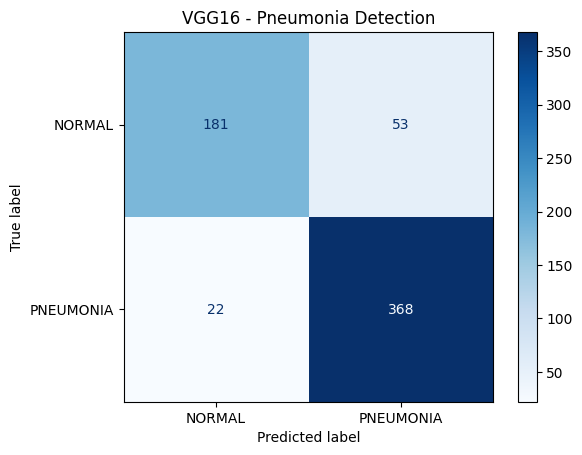

In [10]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on unseen test images
test_data.reset()
y_prob = model.predict(test_data)
y_pred = (y_prob.ravel() >= 0.5).astype(int)
y_true = test_data.classes

# Evaluation metrics
print("Test Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues")
plt.title("VGG16 - Pneumonia Detection")
plt.show()


In [11]:

model.save("/content/best_pneumonia_model.keras")

print("Model saved successfully!")


Model saved successfully!


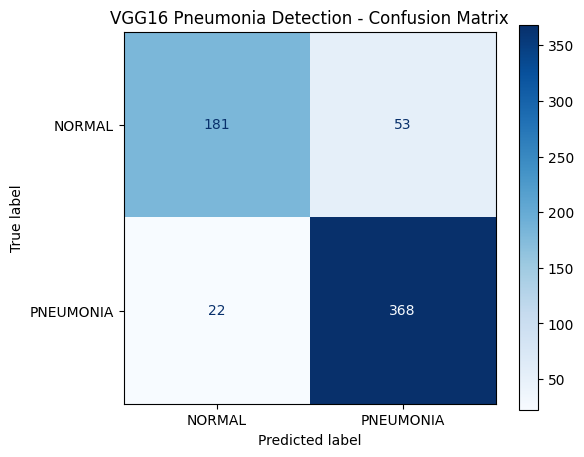

Model and confusion matrix saved successfully!


In [12]:

# Save trained model
model.save("/content/best_pneumonia_model.keras")

# Save confusion matrix as image
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
).plot(cmap="Blues", ax=ax)

plt.title("VGG16 Pneumonia Detection - Confusion Matrix")
plt.savefig("/content/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Model and confusion matrix saved successfully!")


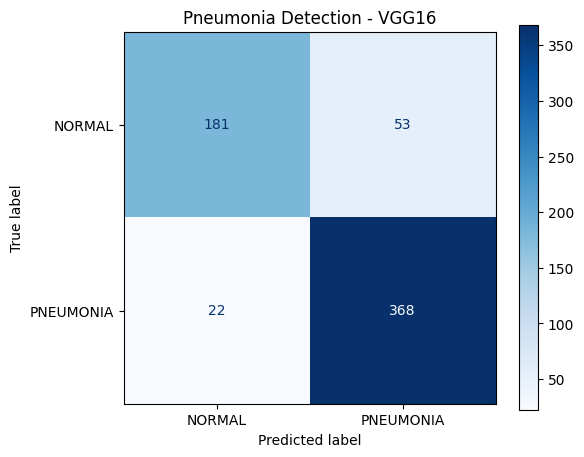

In [13]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
).plot(cmap="Blues", ax=ax)

plt.title("Pneumonia Detection - VGG16")
plt.savefig("/content/confusion_matrix.png", dpi=300)
plt.show()


In [14]:

from google.colab import files

files.download("/content/best_pneumonia_model.keras")
files.download("/content/confusion_matrix.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>